# Exploración complementaria para el informe

Este notebook genera figuras descriptivas adicionales para el informe final.

> **Nota:** a diferencia de [`analisis_exploratorio.ipynb`](analisis_exploratorio.ipynb), aquí se usa el **conjunto completo** (2,325 registros estudiante-intento, 2019–2022), porque el objetivo es describir a la población del curso. Las decisiones de modelado se tomaron únicamente con el conjunto de entrenamiento.

**Entrada:** `Datos/notas_pensamiento_cuantitativo.csv` · **Salidas:** figuras en [`figuras/`](figuras/) (`tasa_reprobacion_veces_curso.png`, `boxplot_notafinal_veces_curso.png`, `tasa_reprobacion_genero.png`, `boxplot_mediana_parciales.png`)

In [1]:
# Librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
import os
os.makedirs("figuras", exist_ok=True)  # todas las figuras se guardan en figuras/

In [2]:
# Carga del dataset completo
datos = pd.read_csv('../../Datos/notas_pensamiento_cuantitativo.csv')

## Variable objetivo
En total hay 2,010 aprobados y 315 reprobados (13.5 %).

In [3]:
# Distribución de la variable objetivo
datos["Aprobado"].value_counts()

Aprobado
1    2010
0     315
Name: count, dtype: int64

## Número de intento
Entre los **reprobados**, la mayoría (186 de 315) cursaba la materia por segunda vez. Entre los **aprobados**, casi todos (1,972 de 2,010) lo lograron en el primer intento y ninguno necesitó más de dos.

In [4]:
# Intentos de los reprobados
datos[datos['Aprobado'] == 0]['veces_curso'].value_counts()

veces_curso
2    186
1    111
4     10
3      8
Name: count, dtype: int64

In [5]:
# Intentos de los aprobados
datos[datos['Aprobado'] == 1]['veces_curso'].value_counts()

veces_curso
1    1972
2      38
Name: count, dtype: int64

Distribución por género: 1,477 hombres y 848 mujeres.

In [6]:
# Estudiantes por género
datos['Genero'].value_counts()

Genero
MASCULINO    1477
FEMENINO      848
Name: count, dtype: int64

Tasa de reprobación según el número de intento. **Decisión:** agrupamos el tercer y el cuarto intento en "3 o más" porque son muy pocos casos (18 estudiantes, todos reprobados).

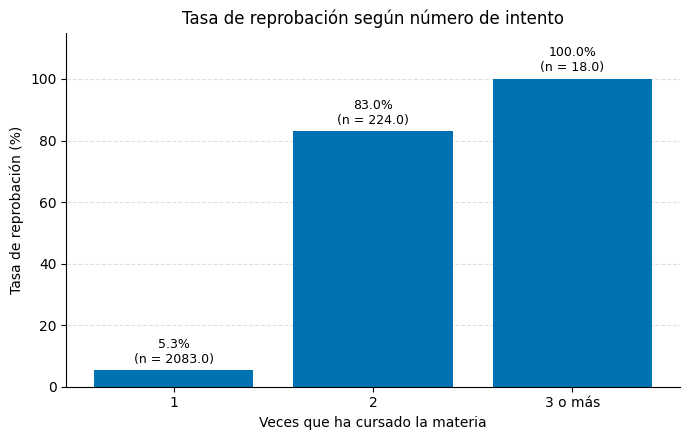

In [ ]:
# Tasa de reprobación según el número de intento, agrupando 3 y 4 intentos

d = datos.copy()
d["veces_cat"] = d["veces_curso"].clip(upper=3).map({1: "1", 2: "2", 3: "3 o más"})
tabla = d.groupby("veces_cat").agg(n=("Aprobado", "size"),
                                   tasa=("Aprobado", lambda s: (s == 0).mean()))

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(tabla.index, tabla["tasa"] * 100, color="#0072B2")
for b, (n, t) in zip(barras, tabla[["n", "tasa"]].values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5,
            f"{t:.1%}\n(n = {n})", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Veces que ha cursado la materia")
ax.set_ylabel("Tasa de reprobación (%)")
ax.set_ylim(0, 115)
ax.set_title("Tasa de reprobación según número de intento")
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figuras/tasa_reprobacion_veces_curso.png", dpi=200, bbox_inches="tight")

In [8]:
# Etiquetas alternativas para los intentos
d["veces_cat"] = d["veces_curso"].clip(upper=3).map(
    {1: "Primer intento", 2: "Segundo intento", 3: "Tercer intento o más"}
)
tabla = tabla.reindex(["Primer intento", "Segundo intento", "Tercer intento o más"])

ax.set_xlabel("Número de intento")
ax.set_title("Tasa de reprobación según número de intento")

Text(0.5, 1.0, 'Tasa de reprobación según número de intento')

Distribución de la nota final según el número de intento.

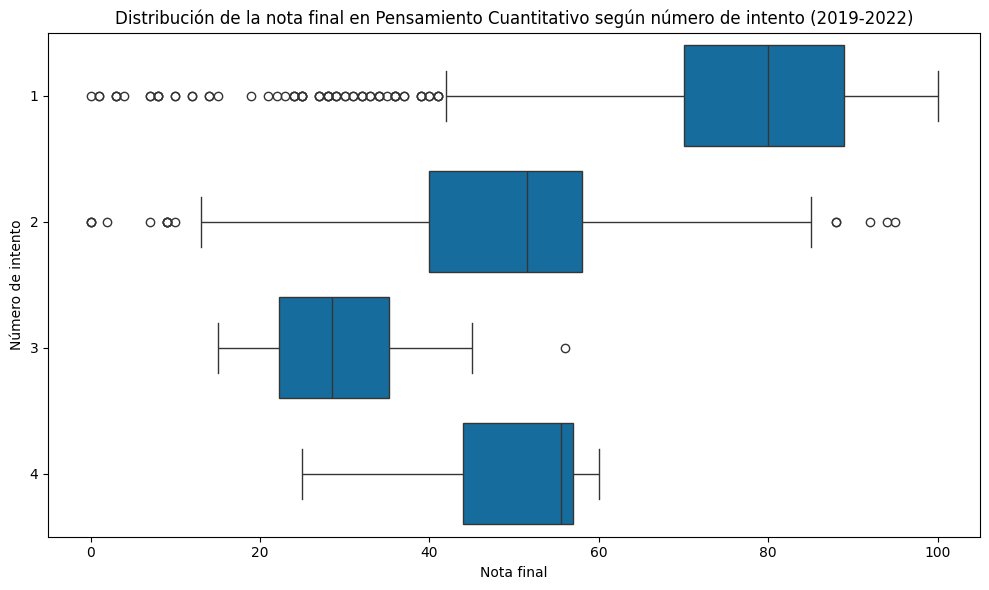

In [9]:
# Nota final según el número de intento
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=datos,
    x='NotaFinal',
    y='veces_curso',
    orient='h',
    color="#0072B2",
    order=sorted(datos['veces_curso'].dropna().unique()),
    ax=ax
)
ax.set_xlabel('Nota final')
ax.set_ylabel('Número de intento')
ax.set_title('Distribución de la nota final en Pensamiento Cuantitativo según número de intento (2019-2022)')

plt.tight_layout()
plt.savefig("figuras/boxplot_notafinal_veces_curso.png", dpi=200, bbox_inches="tight")
plt.show()

Los 10 estudiantes que cursaban la materia por cuarta vez reprobaron (notas entre 25 y 60).

In [10]:
# Estudiantes en su cuarto intento
datos[datos['veces_curso'] == 4][['NotaFinal', 'Aprobado']]

,NotaFinal,Aprobado
246,42.0,0
321,34.0,0
1492,55.0,0
1665,57.0,0
1844,50.0,0
1906,60.0,0
1970,57.0,0
2046,25.0,0
2206,56.0,0
2216,57.0,0


## Género
Tasa de reprobación: 15.1 % en hombres (223 de 1,477) y 10.8 % en mujeres (92 de 848).

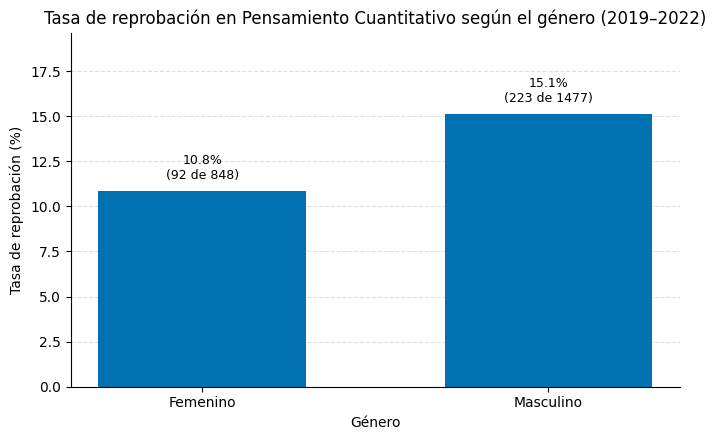

In [11]:
# Tasa de reprobación según el género
genero = (
    datos.groupby('Genero')['Aprobado']
    .agg(n='size', reprobados=lambda s: (s == 0).sum())
    .assign(tasa=lambda d: 100 * d['reprobados'] / d['n'])
)
genero.index = genero.index.str.capitalize()   # FEMENINO -> Femenino

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(genero.index, genero['tasa'], color="#0072B2", width=0.6)

for barra, (_, fila) in zip(barras, genero.iterrows()):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.5,
            f"{fila['tasa']:.1f}%\n({int(fila['reprobados'])} de {int(fila['n'])})",
            ha='center', va='bottom', fontsize=9)

ax.set_ylim(0, genero['tasa'].max() * 1.3)
ax.set_xlabel('Género')
ax.set_ylabel('Tasa de reprobación (%)')
ax.set_title('Tasa de reprobación en Pensamiento Cuantitativo según el género (2019–2022)')
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig('figuras/tasa_reprobacion_genero.png', dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Estudiantes por género
datos['Genero'].value_counts()

Genero
MASCULINO    1477
FEMENINO      848
Name: count, dtype: int64

In [13]:
# Reprobados por género
datos[datos['Aprobado'] == 0]['Genero'].value_counts()

Genero
MASCULINO    223
FEMENINO      92
Name: count, dtype: int64

In [14]:
# Columnas disponibles
datos.columns

Index(['Est_ID', 'PAA', 'Colegio', 'TituloNivelMedio', 'NotaFinal', 'Aprobado',
       'Genero', 'EstadoCurso', 'veces_curso', 'Anio', 'Seccion',
       'porcentaje_acum_actividades_mes_1',
       'porcentaje_acum_actividades_mes_2',
       'porcentaje_acum_actividades_mes_3',
       'porcentaje_acum_actividades_mes_4',
       'porcentaje_acum_actividades_mes_5', 'entregas_tarde_acum_mes_1',
       'entregas_tarde_acum_mes_2', 'entregas_tarde_acum_mes_3',
       'entregas_tarde_acum_mes_4', 'entregas_tarde_acum_mes_5',
       'nota_examen_mes_2', 'nota_examen_mes_3', 'nota_examen_mes_4',
       'nota_examen_mes_5', 'delta_actividades_mes_2',
       'delta_actividades_mes_3', 'delta_actividades_mes_4',
       'delta_actividades_mes_5', 'z_porcentaje_acum_actividades_mes_1',
       'z_porcentaje_acum_actividades_mes_2',
       'z_porcentaje_acum_actividades_mes_3',
       'z_porcentaje_acum_actividades_mes_4',
       'z_porcentaje_acum_actividades_mes_5', 'z_nota_examen_mes_2',
       'z

## Exámenes parciales vs. resultado
Resumimos el desempeño en exámenes con la **mediana** de los parciales disponibles de cada estudiante (se ignoran los parciales faltantes). Usamos la mediana para que un solo parcial atípico no domine el resumen.

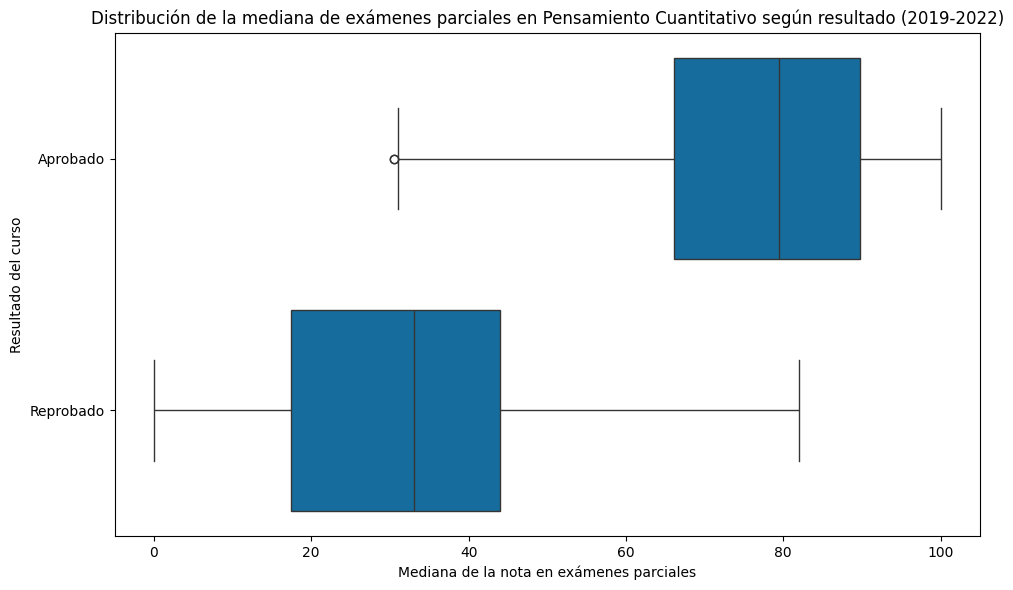

In [15]:
# Mediana de los parciales según el resultado del curso
cols_parciales = [
    'nota_examen_mes_2', 'nota_examen_mes_3',
    'nota_examen_mes_4', 'nota_examen_mes_5',
]

# Mediana de los parciales por estudiante (ignora parciales faltantes)
datos['mediana_parciales'] = datos[cols_parciales].median(axis=1, skipna=True)
datos['Resultado'] = datos['Aprobado'].map({1: 'Aprobado', 0: 'Reprobado'})

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=datos,
    x='mediana_parciales',
    y='Resultado',
    orient='h',
    color="#0072B2",
    order=['Aprobado', 'Reprobado'],
    ax=ax
)
ax.set_xlabel('Mediana de la nota en exámenes parciales')
ax.set_ylabel('Resultado del curso')
ax.set_title('Distribución de la mediana de exámenes parciales en Pensamiento Cuantitativo según resultado (2019-2022)')

plt.tight_layout()
plt.savefig("figuras/boxplot_mediana_parciales.png", dpi=200, bbox_inches="tight")
plt.show()

Hay 4 estudiantes con mediana de parciales mayor a 70 que aun así reprobaron. Revisamos su desempeño en actividades:

In [16]:
# Reprobados con mediana de parciales mayor a 70
datos[(datos['mediana_parciales'] > 70) & (datos['Aprobado'] == 0)][['mediana_parciales', 'NotaFinal', 'Aprobado', 'Est_ID']]

,mediana_parciales,NotaFinal,Aprobado,Est_ID
1326,77.5,58.0,0,432.0
1350,74.5,59.0,0,1259.0
2254,73.5,55.0,0,135.0
2282,82.0,54.0,0,829.0


In [17]:
# Porcentaje en actividades de esos estudiantes
datos[datos['Est_ID'].isin([432, 1259, 135,829 ])][['porcentaje_acum_actividades_mes_1',
       'porcentaje_acum_actividades_mes_2',
       'porcentaje_acum_actividades_mes_3',
       'porcentaje_acum_actividades_mes_4',
       'porcentaje_acum_actividades_mes_5']]

,porcentaje_acum_actividades_mes_1,porcentaje_acum_actividades_mes_2,porcentaje_acum_actividades_mes_3,porcentaje_acum_actividades_mes_4,porcentaje_acum_actividades_mes_5
1326,66.000000,44.529412,43.380282,44.881720,40.309091
1350,46.000000,62.970588,65.605634,56.537634,50.672727
2253,54.421053,49.407407,46.139535,46.588889,38.827273
2254,18.886427,27.764397,34.421812,49.520798,50.152052
2281,45.000000,41.888889,33.000000,43.232143,35.041818
2282,3.136039,8.709361,13.068417,45.227621,43.793447


En general, estos estudiantes tienen porcentajes bajos en actividades: un buen desempeño en los exámenes no basta para aprobar, porque las actividades (zona) también pesan en el resultado. Esto respalda incluir el porcentaje acumulado en actividades como variable del modelo.